# Week 6 — Lab

**3 hours.** Work through in order. You are not expected to finish everything.

| Part | Time | What |
|---|---|---|
| Warm-up | 15 min | Fix three broken programs |
| Drills | 60 min | Short tasks on every topic this week, plus two challenges |
| Break | 10 min | |
| Mini-project | 80 min | Your Record Check, rebuilt with pandas |
| Wrap-up | 15 min | Cheat sheet notes, photo, push to GitHub |

**Aiming for a pass?** Do all the drills in Topics 1–4 and the Threshold version of the mini-project.
**Aiming higher?** Add the Typical version of the mini-project.
**Aiming for a first?** Add the two Challenge drills and the Excellent version of the mini-project.

> ### Before you start: install pandas
> This week needs `pandas` and `matplotlib`. If you have not set up your virtual environment yet,
> follow the *virtual environment and packages* section at the end of the
> [setup guide](https://anna29.github.io/CST1510/setup-guide.html) first, then choose `.venv` as the kernel
> for this notebook (**Select Kernel**, top right).

> ### What you submit this week
> Both files stay in this `LAB` folder and are pushed to GitHub at the end of the lab.
>
> 1. **This notebook**, with your drill answers and the photo of your cheat sheet pasted in at the very end
> 2. **`template.py`**, your completed mini-project
>
> The warm-up is not submitted.
>
> If your mini-project uses your own data file, keep it in this `LAB` folder so it is pushed too.

> ### If you are stuck
> 1. Read the **last line** of the error.
> 2. Check the *Common mistakes* table in that topic's walkthrough.
> 3. Run the matching file in that topic's `examples/` folder.
> 4. Ask, and say what the last line of the error said.

---
# Warm-up · 15 min

Open the `warmup/` folder. Each file is **broken on purpose**. For each one:

1. Run it and read the **last line** of the error first.
2. Look at the line number it gives you.
3. Fix it and run it again.

| Error you will meet | Usually means |
|---|---|
| `KeyError` | the column name does not match exactly (check capital letters) |
| `ValueError` | if it says *All arrays must be of the same length*, the columns have different numbers of values |
| `TypeError` | the column holds numbers stored as text: check `.dtypes` |

---
# Drills

The drills follow the topics from the workshop, in the same order. Each one is short and
tests one idea. Run your cell and compare it with the expected output.

---
## Topic 1 · Series and DataFrame
*Walkthrough: `01 - Series and DataFrame`*

### D1. A Series

1. Run `import pandas as pd`.
2. Create `values = pd.Series([87, 120, 45])` and print it.
3. Print `values.max()`.

**Expected output:**
```
0     87
1    120
2     45
dtype: int64
120
```

In [2]:
# D1
import pandas as pd
values = pd.Series([87, 120, 45])
print(values)
print(values.max())

0     87
1    120
2     45
dtype: int64
120


### D2. A DataFrame from a dict

1. Create a DataFrame from a dict of lists, with three columns:
   `label` (`"R-001"`, `"R-002"`, `"R-003"`), `value` (`87`, `120`, `45`) and `limit` (`100`, `100`, `100`).
2. Print it, then print its `.shape`.

**Expected output:** a table with 3 rows and 3 columns, then `(3, 3)`

In [3]:
# D2
df = pd.DataFrame({         # turns dictionary into table
   "label": ["R-001", "R-002", "R-003"],
   "value": [87, 120, 45],
   "limit": [100, 100, 100] 
})

print(df)
print(df.shape)

   label  value  limit
0  R-001     87    100
1  R-002    120    100
2  R-003     45    100
(3, 3)


### D3. Read a whole file with `read_csv()`

1. Read `records_sample.csv` (in this `LAB` folder) into a DataFrame called `df`.
2. Print `df`, then print `df.dtypes`.

**Expected output:** a table with 6 records (`R-001` to `R-006`), then the types:
`value` and `limit` are `int64`, and `label` is text (shown as `object`, or `str` in newer versions of pandas).

In [4]:
# D3
df = pd.read_csv("records_sample.csv")

print(df)
print(df.dtypes)    # dtypes is data types
# i initially mistyped df.dtypes as df.types and it showed an AttributeError, need to watch out for wrong spellings

   label  value  limit
0  R-001     87    100
1  R-002    120    100
2  R-003     45    100
3  R-004     93    100
4  R-005    101    100
5  R-006     60    100
label      str
value    int64
limit    int64
dtype: object


### D4. Add a column, without a loop

Add a `percent` column to `df`: `(value / limit) * 100`. Print `df`.

**Expected output:** the `percent` column holds `87.0`, `120.0`, `45.0`, `93.0`, `101.0`, `60.0`.

In [5]:
# D4
df["percent"] = (df["value"] / df["limit"] * 100)   # the quotes are important ***
print(df)


   label  value  limit  percent
0  R-001     87    100     87.0
1  R-002    120    100    120.0
2  R-003     45    100     45.0
3  R-004     93    100     93.0
4  R-005    101    100    101.0
5  R-006     60    100     60.0


---
## Topic 2 · Selecting and filtering
*Walkthrough: `02 - Selecting and Filtering`*

### D5. `iloc` and `loc`

1. Print the `label` of the first row, using `df.iloc[0]["label"]`.
2. Print the `value` in the row with index `2`, using `df.loc[2, "value"]`.

**Expected output:** `R-001`, then `45`

In [6]:
# D5
# iloc finds a row by its position, 0 is the first row then ["label"] picks the label position from the row
print(df.iloc[0]["label"])
# loc finds a spot by index label and column name i.e. loc[row column]
print(df.loc[2, "value"])

R-001
45


### D6. Selecting columns

1. Print just the `label` column (one pair of brackets).
2. Print just the `label` and `percent` columns (a list inside the brackets).

**Expected output:** first one column of labels, then a two-column table.

In [7]:
# D6
# one pair of brackets and one column gives one column as a Series
print(df["label"])
# a list inside the brackets. Two pairs of brackets gives a table i.e. the DataFrame
print(df[["label", "percent"]])   # 2 pairs of brackets!!!!!!
# I initially put one bracket and I encountered a KeyError
# i observed two things, a Series and a DataFrame

0    R-001
1    R-002
2    R-003
3    R-004
4    R-005
5    R-006
Name: label, dtype: str
   label  percent
0  R-001     87.0
1  R-002    120.0
2  R-003     45.0
3  R-004     93.0
4  R-005    101.0
5  R-006     60.0


### D7. Filter rows with a condition

1. Keep only the rows where `percent` is 100 or more, using a condition inside `df[...]`. Print them.
2. Print how many rows that is, with `len()`.

**Expected output:** the rows for `R-002` and `R-005`, then `2`

In [8]:
# D7
over = df[df["percent"] >= 100] # df["percent"]... checks every row and gives either True or False then df[] keeps the rows which give True
print(over)
print(len(over))    # len() counts the rows that were kept

   label  value  limit  percent
1  R-002    120    100    120.0
4  R-005    101    100    101.0
2


### D8. Combine conditions with `&` and `|`

1. Print the rows where `percent` is 90 or more **and** less than 100.
2. Print the rows where `percent` is less than 50 **or** more than 110.

*Put brackets round each condition, and use `&` and `|`, not `and` / `or`.*

**Expected output:** first only `R-004`, then `R-002` and `R-003`

In [ ]:
# D8
# percent is 90 or more and les than 100, both conditions must be true
print(df[(df["percent"] >= 90) & (df["percent"] < 100)])
# percent is less than 50 or more than hundred, | means or so at least one condition must be true
print(df[(df["percent"] < 50) | (df["percent"] > 110)])

   label  value  limit  percent
3  R-004     93    100     93.0
   label  value  limit  percent
1  R-002    120    100    120.0
2  R-003     45    100     45.0


---
## Topic 3 · Grouping, sorting and aggregating
*Walkthrough: `03 - Grouping, Sorting and Aggregating`*

### D9. Sort

Sort `df` by `percent`, highest first, and print it.

**Expected output:** the labels in this order: `R-002`, `R-005`, `R-004`, `R-001`, `R-006`, `R-003`

In [ ]:
# D9
# sort_values sorts the rows by the column named in the brackets
# ascending=False means highest first, (opposite the default which is lowest first)
sorted_df = df.sort_values("percent", ascending = False)  # ***capital letter F
print(sorted_df)

   label  value  limit  percent
1  R-002    120    100    120.0
4  R-005    101    100    101.0
3  R-004     93    100     93.0
0  R-001     87    100     87.0
5  R-006     60    100     60.0
2  R-003     45    100     45.0


### D10. `groupby()`, `.agg()` and `value_counts()`

1. Add a column `over` that is `True` when `percent` is 100 or more: `df["over"] = df["percent"] >= 100`
2. Group by `over` and print the mean, max and min of `percent` for each group, using `.agg(["mean", "max", "min"])`.
3. Print `df["over"].value_counts()`.

**Expected output:**
```
         mean    max    min
over
False   71.25   93.0   45.0
True   110.50  120.0  101.0
```
then `False` 4 and `True` 2.

In [ ]:
# D10
df["over"] = df["percent"] >= 100   # this line is true when the rcord is at or over the limit
# group the rows into piles using "over"
print(df.groupby("over")["percent"].agg(["mean", "max", "min"]))
print(df["over"].value_counts()) 

         mean    max    min
over                       
False   71.25   93.0   45.0
True   110.50  120.0  101.0
over
False    4
True     2
Name: count, dtype: int64


---
## Topic 4 · Apply, lambda and finishing up
*Walkthrough: `04 - Apply, Lambda and Finishing Up`*

### D11. A lambda

1. Write `double = lambda x: x * 2` and print `double(21)`.
2. Underneath, write the same thing as a normal `def` function called `double_def`, and print `double_def(21)`.

**Expected output:** `42`, then `42`

In [50]:
# D11
double = lambda x: x * 2    # takes x and gives back x doubled/ x times 2
print(double(21))

def double_def(x):
    return x * 2
print(double_def(21))

42
42


### D12. `.apply()` with a lambda

1. Add a `status` column to `df` using `df["percent"].apply(lambda p: ...)`:
   `"OVER LIMIT"` if 100 or more, `"WARNING"` if 90 or more, otherwise `"OK"`.
2. Print just the `label` and `status` columns.
3. Print `df["status"].value_counts()`.

**Expected output:** `R-001` OK, `R-002` OVER LIMIT, `R-003` OK, `R-004` WARNING, `R-005` OVER LIMIT,
`R-006` OK; then `OK` 3, `OVER LIMIT` 2, `WARNING` 1.

In [ ]:
# D12
# apply runs lambda on every value in the percent column
df["status"] = df["percent"].apply(
    lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK"
)
print(df[["label", "status"]])
print(df["status"].value_counts())

   label      status
0  R-001          OK
1  R-002  OVER LIMIT
2  R-003          OK
3  R-004     WARNING
4  R-005  OVER LIMIT
5  R-006          OK
status
OK            3
OVER LIMIT    2
WARNING       1
Name: count, dtype: int64


### D13. Summarise and save

1. Print `df.describe()`.
2. Save `df` to a new file with `df.to_csv("records_report.csv", index=False)`.

**Expected output:** a summary table (count, mean, min, max and so on) for the number columns, and a new file
`records_report.csv` in this `LAB` folder.

In [76]:
# D13
# describe() gives a quick summary/ overview of the number columns
print(df.describe())
df.to_csv("records_sample.csv", index=False)

            value  limit     percent
count    6.000000    6.0    6.000000
mean    84.333333  100.0   84.333333
std     27.463916    0.0   27.463916
min     45.000000  100.0   45.000000
25%     66.750000  100.0   66.750000
50%     90.000000  100.0   90.000000
75%     99.000000  100.0   99.000000
max    120.000000  100.0  120.000000


### D14. A first chart

1. Run `import matplotlib.pyplot as plt`.
2. Make a bar chart of the status counts: `df["status"].value_counts().plot(kind="bar")`
3. Give it a title with `plt.title(...)`, save it with `plt.savefig("status_counts.png")`, then `plt.show()`.

**Expected output:** a bar chart with three bars (OK, OVER LIMIT, WARNING), and a new file `status_counts.png`.

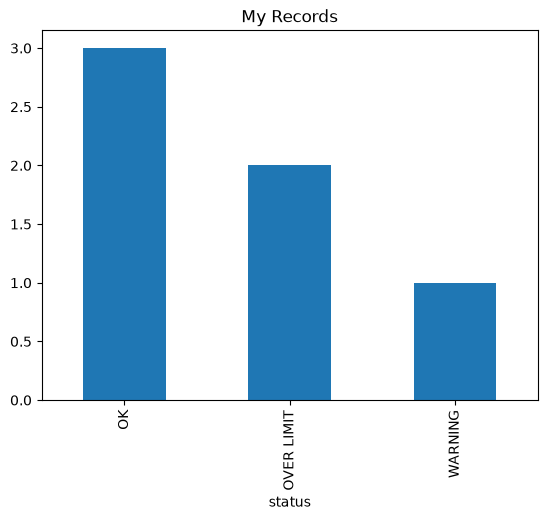

In [81]:
# D14
import matplotlib.pyplot as plt
# ModuleNotFoundError, i had to first install by running python -m pip install matplotlib
df["status"].value_counts().plot(kind="bar")
plt.title("My Records")
plt.savefig("status_counts.png")
plt.show()

---
## Challenge · for a first

*These combine several ideas from this week. There are no step-by-step instructions.*

### C1. Load, filter, sort and save

Starting again from `records_sample.csv`: add `percent` and `status`, keep only the `OVER LIMIT` rows,
sort them by `percent` (highest first), and save the result to `over_limit.csv`. Print the result too.

**Expected output:** two rows, `R-002` (120.0) then `R-005` (101.0)

In [ ]:
# C1
# loading the given file
df =pd.read_csv("records_sample.csv")
# adding percent and status
df["percent"] = (df["value"] / df["limit"]) * 100
df["status"] = df["percent"].apply(
    lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK"
)
# keep only the OVR LIMIT rows **
over = df[df["status"] == "OVER LIMIT"]
over = over.sort_values("percent", ascending=False)
over.to_csv("over_limit.csv", index=False)
print(over)

   label  value  limit  percent  over      status
1  R-002    120    100    120.0  True  OVER LIMIT
4  R-005    101    100    101.0  True  OVER LIMIT


### C2. Average per status

Using your DataFrame with the `status` column, print the average `percent` for each status,
rounded to 1 decimal place.

**Expected output:**
```
status
OK             64.0
OVER LIMIT    110.5
WARNING        93.0
```

In [86]:
# C2
print(df.groupby("status")["percent"].mean().round(1))

status
OK             64.0
OVER LIMIT    110.5
WARNING        93.0
Name: percent, dtype: float64


---
# Mini-project · 80 min

Open **`template.py`** (in this `LAB` folder). It has the structure already — you fill in the marked sections.

## Choose your lane

Pick **one**. All three are the same program with different words — make your own
CSV, header row plus at least 5 data rows.

| Lane | Your columns | Example row |
|---|---|---|
| **AI / Data Science** | `dataset,rows_loaded,rows_expected` | `survey_2026,1187,1200` |
| **Cyber Security** | `source_ip,failed_logins,total_attempts` | `10.0.0.5,12,400` |
| **IT** | `hostname,used_gb,total_gb` | `srv-01,87,120` |

## What to build

**Threshold — pass standard.** Read your CSV with `pd.read_csv()`. Add a
`percent` column. Print the DataFrame.

**Typical.** Add a `status` column using `.apply()` with a lambda (`"OVER
LIMIT"` / `"WARNING"` / `"OK"`). Print only the rows that are not `"OK"`, using a
boolean filter — no loop.

**Excellent.** Group by `status` and print a count per group. Save the full
DataFrame to a new CSV with `.to_csv()`. Produce one bar chart of the counts per
status and save it as a PNG.

## Rules

- **`&` / `\|`, not `and`/`or`**, when combining more than one condition — with
  brackets around each side.
- The lambda should be one expression only. If your logic needs more than that,
  write a named function instead and `.apply()` that.
- No loops for anything this week's tools already do in one line.

## When it works

1. Check the `percent` and `status` columns by hand for one row.
2. Check the column names in your code match your CSV's header exactly — watch
   case.

---
# Optional revision · not submitted

If you have time, answer these on paper. They are good revision, but they are not checked.

- Why does `df[condition1 and condition2]` fail, when `df[(condition1) & (condition2)]` works?
- What is a lambda, and when would you use a named function instead?
- What does `groupby("column")` do on its own, before you ask it for a summary?
- Which error did you meet most today, and what did it turn out to mean?

---
# Wrap-up · 15 min

## 1. This week's cheat sheet

On the **same sheet of paper** you started in Week 1, add your handwritten notes for this week.
This week's cheat sheet should contain notes about:

1. **Series and DataFrame:** `pd.Series([...])`, `pd.DataFrame({...})`, `pd.read_csv(path)`, `.dtypes`, `.shape`
2. **New columns without a loop:** `df["percent"] = (df["value"] / df["limit"]) * 100`
3. **Selecting:** `df["col"]`, `df[["a", "b"]]`, `df.iloc[row]` (position), `df.loc[row, "col"]` (label)
4. **Filtering:** `df[df["col"] >= x]`; combine with `&` and `|`, with brackets round each condition
5. **Sorting:** `df.sort_values("col", ascending=False)`
6. **Grouping:** `df.groupby("col")["other"].agg(["mean", "max"])` and `df["col"].value_counts()`
7. **Lambda and `.apply()`:** `df["col"].apply(lambda x: ... if ... else ...)`
8. **Finishing up:** `df.describe()`, `df.to_csv(path, index=False)`, `.plot(kind="bar")`

Write them in your own words, with a short example for each. Do not copy from the slides.

---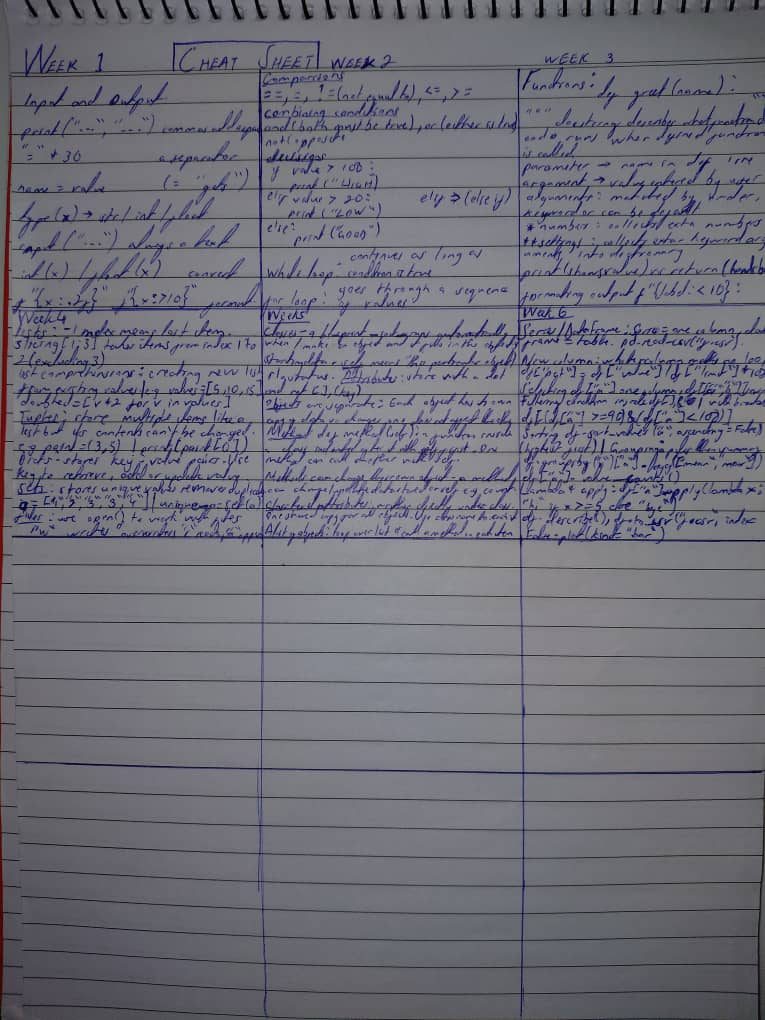
## 2. Add your cheat sheet notes here

Take a clear photo of your **whole** cheat sheet page (your notes for Weeks 1–6), then click into
this cell and paste it (`Ctrl+V` / `Cmd+V`), or drag the image file in.

*(paste here)*

---
## 3. Push to GitHub

Save this notebook and `template.py`. Then open the `CST1510` folder in VS Code and run these
three commands in its terminal:

```
git add .
git commit -m "Week 6 lab and mini-project"
git push
```

Finally, open your repository on GitHub and check that this week's `LAB` folder is there.
If it is not, type `pwd` in the terminal to check which folder you are in.